# Benchmark des algorithmes de tri

+ Visualisations des mesures de `data/results.csv`, avec la configuration
+ de `data/pc_config.txt`. Exécuter les cellules dans l'ordre, depuis `scripts/`
+ ou la racine du projet. Les figures PNG sont enregistrées dans `data/`.

Les temps du CSV sont en **secondes**. `Temps_s` conserve cette unité et `Temps`
contient les millisecondes pour G1–G3. G4 utilise les secondes, puis exprime les
rapports en nanosecondes pour faciliter la lecture. Les mesures ne sont pas modifiées.


In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from IPython.display import display, Markdown

# Chargement portable : notebook lancé depuis scripts/, la racine ou src/.
candidates = [Path.cwd() / 'data', Path.cwd().parent / 'data']
DATA_DIR = next((p.resolve() for p in candidates if (p / 'results.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('results.csv introuvable : lancer le notebook depuis scripts/ ou la racine du projet.')

df = pd.read_csv(DATA_DIR / 'results.csv')
df.columns = df.columns.str.strip()
required = {'Taille', 'Scenario', 'Nom_Algo', 'Temps'}
if not required.issubset(df.columns):
    raise ValueError(f'Colonnes manquantes : {required - set(df.columns)}')
for col in ['Scenario', 'Nom_Algo']:
    df[col] = df[col].astype('string').str.strip()
for col in ['Taille', 'Temps']:
    df[col] = pd.to_numeric(df[col], errors='raise')
if df[list(required)].isna().any().any():
    raise ValueError('Le CSV contient des valeurs manquantes.')
if not np.isfinite(df[['Taille', 'Temps']].to_numpy()).all():
    raise ValueError('Les tailles et les temps doivent être finis.')
if (df['Taille'] <= 1).any() or (df['Taille'] % 1 != 0).any() or (df['Temps'] <= 0).any():
    raise ValueError('Il faut N entier > 1 et T > 0 pour les logarithmes. Aucun zéro ne sera remplacé artificiellement.')
if df.duplicated(['Taille', 'Scenario', 'Nom_Algo']).any():
    raise ValueError('Plusieurs mesures par triplet : choisir explicitement une agrégation avant le tracé.')

df['Temps_s'] = df['Temps'].copy()
df['Temps'] = df['Temps_s'] * 1000  # millisecondes ; source conservée dans Temps_s
quadratic = ['Selection Sort', 'Bubble Sort', 'Insertion Sort']
fast = ['Quick Sort', 'Merge Sort']
algos = quadratic + fast
scenarios = ['Aleatoire', 'Trie', 'Inverse']
scenario_labels = {'Aleatoire': 'Aléatoire', 'Trie': 'Trié', 'Inverse': 'Inversé'}
if set(df['Nom_Algo']) != set(algos) or set(df['Scenario']) != set(scenarios):
    raise ValueError('Le benchmark doit contenir les cinq algorithmes et les trois scénarios attendus.')

# Intersection réelle des tailles : même poids pour chaque taille en G2 bis.
size_sets = [set(df.loc[(df['Nom_Algo'] == a) & (df['Scenario'] == s), 'Taille'])
             for a in algos for s in scenarios]
common_sizes = sorted(set.intersection(*size_sets))
if not common_sizes:
    raise ValueError('Aucune taille commune aux cinq algorithmes et aux trois scénarios.')

colors = {'Selection Sort': '#b94743', 'Bubble Sort': '#d77a13',
          'Insertion Sort': '#7d579a', 'Quick Sort': '#168477', 'Merge Sort': '#2863a3'}
markers = {'Selection Sort': 's', 'Bubble Sort': '^', 'Insertion Sort': 'D',
           'Quick Sort': 'o', 'Merge Sort': 'v'}
scenario_colors = {'Aleatoire': '#2863a3', 'Trie': '#168477', 'Inverse': '#b94743'}
scenario_styles = {'Aleatoire': '-', 'Trie': '--', 'Inverse': '-.'}

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'savefig.facecolor': 'white'})

def format_n(x, _=None):
    return f'{x / 1e6:g}M' if x >= 1e6 else (f'{x / 1e3:g}k' if x >= 1e3 else f'{x:g}')

def format_fr(x, digits=3):
    return f'{x:.{digits}g}'.replace('.', ',')

def save_figure(fig, name):
    fig.savefig(DATA_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'Figure enregistrée : {name}')

print(f'{len(df)} mesures chargées ; temps strictement positifs ; aucun doublon.')
print(f'{len(common_sizes)} tailles communes : ' + ', '.join(format_n(n) for n in common_sizes))
display(df.head())


744 mesures chargées ; temps strictement positifs ; aucun doublon.
10 tailles communes : 10k, 20k, 30k, 40k, 50k, 60k, 70k, 80k, 90k, 100k


,Taille,Scenario,Nom_Algo,Temps,Temps_s
0,10000,Aleatoire,Selection Sort,155.9923,0.155992
1,10000,Aleatoire,Bubble Sort,266.6391,0.266639
2,10000,Aleatoire,Insertion Sort,13.7314,0.013731
3,10000,Aleatoire,Quick Sort,1.6542,0.001654
4,10000,Aleatoire,Merge Sort,1.8917,0.001892


---
## G1. Temps d'exécution par scénario

**En haut : vue complète en log–log.** L'axe des tailles s'étend de 10 000 à
10 millions et l'axe des temps couvre plusieurs ordres de grandeur. Une échelle
linéaire écrasait les petits temps et concentrait les tris quadratiques à gauche.

**En bas : zoom sur les tailles communes**, avec N linéaire et le temps
logarithmique. Les mêmes limites sont utilisées dans les trois scénarios pour
permettre la comparaison. Chaque point représente une mesure ; toutes les
mesures sont tracées, sans extrapolation. L'arrêt des courbes quadratiques à
100 000 correspond à la fin de leurs mesures, pas à un temps nul.


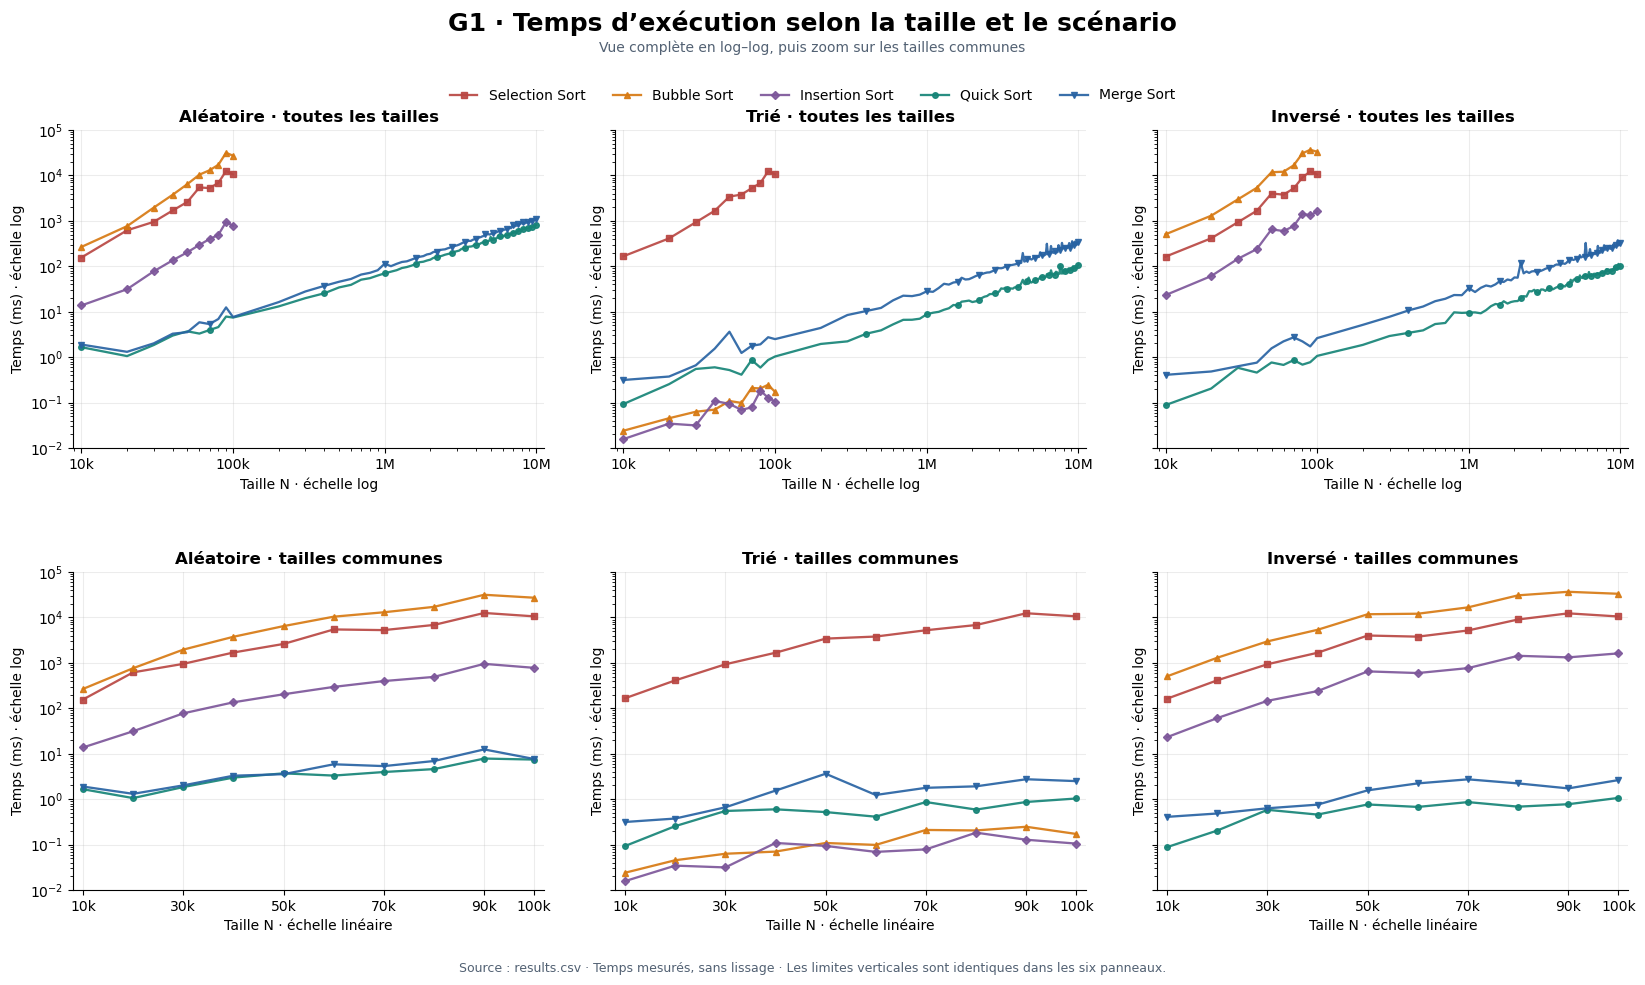

Figure enregistrée : graph1_tris_par_scenario.png


In [2]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharey=True)
fig.subplots_adjust(top=0.86, bottom=0.10, left=0.065, right=0.98, hspace=0.39, wspace=0.15)
fig.suptitle('G1 · Temps d’exécution selon la taille et le scénario', fontsize=18, fontweight='bold', y=0.98)
fig.text(0.5, 0.938, 'Vue complète en log–log, puis zoom sur les tailles communes', ha='center', color='#526173')
ymin = 10 ** np.floor(np.log10(df['Temps'].min()))
ymax = 10 ** np.ceil(np.log10(df['Temps'].max()))

for col, scenario in enumerate(scenarios):
    for row in range(2):
        ax = axes[row, col]
        sub = df[df['Scenario'] == scenario]
        if row == 1:
            sub = sub[sub['Taille'].isin(common_sizes)]
        for algo in algos:
            data = sub[sub['Nom_Algo'] == algo].sort_values('Taille')
            ax.plot(data['Taille'], data['Temps'], label=algo, color=colors[algo],
                    marker=markers[algo], markersize=4, linewidth=1.65,
                    markevery=max(1, len(data) // 18), alpha=0.92)
        ax.set_yscale('log')
        ax.set_ylim(ymin, ymax)
        ax.set_ylabel('Temps (ms) · échelle log')
        if row == 0:
            ax.set_xscale('log')
            ax.set_xlim(df['Taille'].min() * 0.88, df['Taille'].max() * 1.13)
            ax.set_xticks([1e4, 1e5, 1e6, 1e7])
            ax.set_title(scenario_labels[scenario] + ' · toutes les tailles')
            ax.set_xlabel('Taille N · échelle log')
        else:
            ax.set_xlim(min(common_sizes) * 0.8, max(common_sizes) * 1.02)
            ax.set_xticks(common_sizes[::2] + ([common_sizes[-1]] if common_sizes[-1] not in common_sizes[::2] else []))
            ax.set_title(scenario_labels[scenario] + ' · tailles communes')
            ax.set_xlabel('Taille N · échelle linéaire')
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_n))
        ax.xaxis.set_minor_formatter(ticker.NullFormatter())
        ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=9))
        ax.grid(True, which='major', alpha=0.23)
        ax.set_axisbelow(True)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.914), ncol=5, frameon=False)
fig.text(0.5, 0.018, 'Source : results.csv · Temps mesurés, sans lissage · Les limites verticales sont identiques dans les six panneaux.',
         ha='center', fontsize=9, color='#526173')
save_figure(fig, 'graph1_tris_par_scenario.png')


---
## 2️⃣ Impact du scénario sur la performance de chaque algorithme

Pour chaque algorithme, on compare ses performances selon les 3 scénarios.  
Cela met en évidence comment le type de données d'entrée influence le temps d'exécution.
Les axes N et temps sont logarithmiques pour rendre visibles les petits temps, notamment les meilleurs cas de Bubble et Insertion.


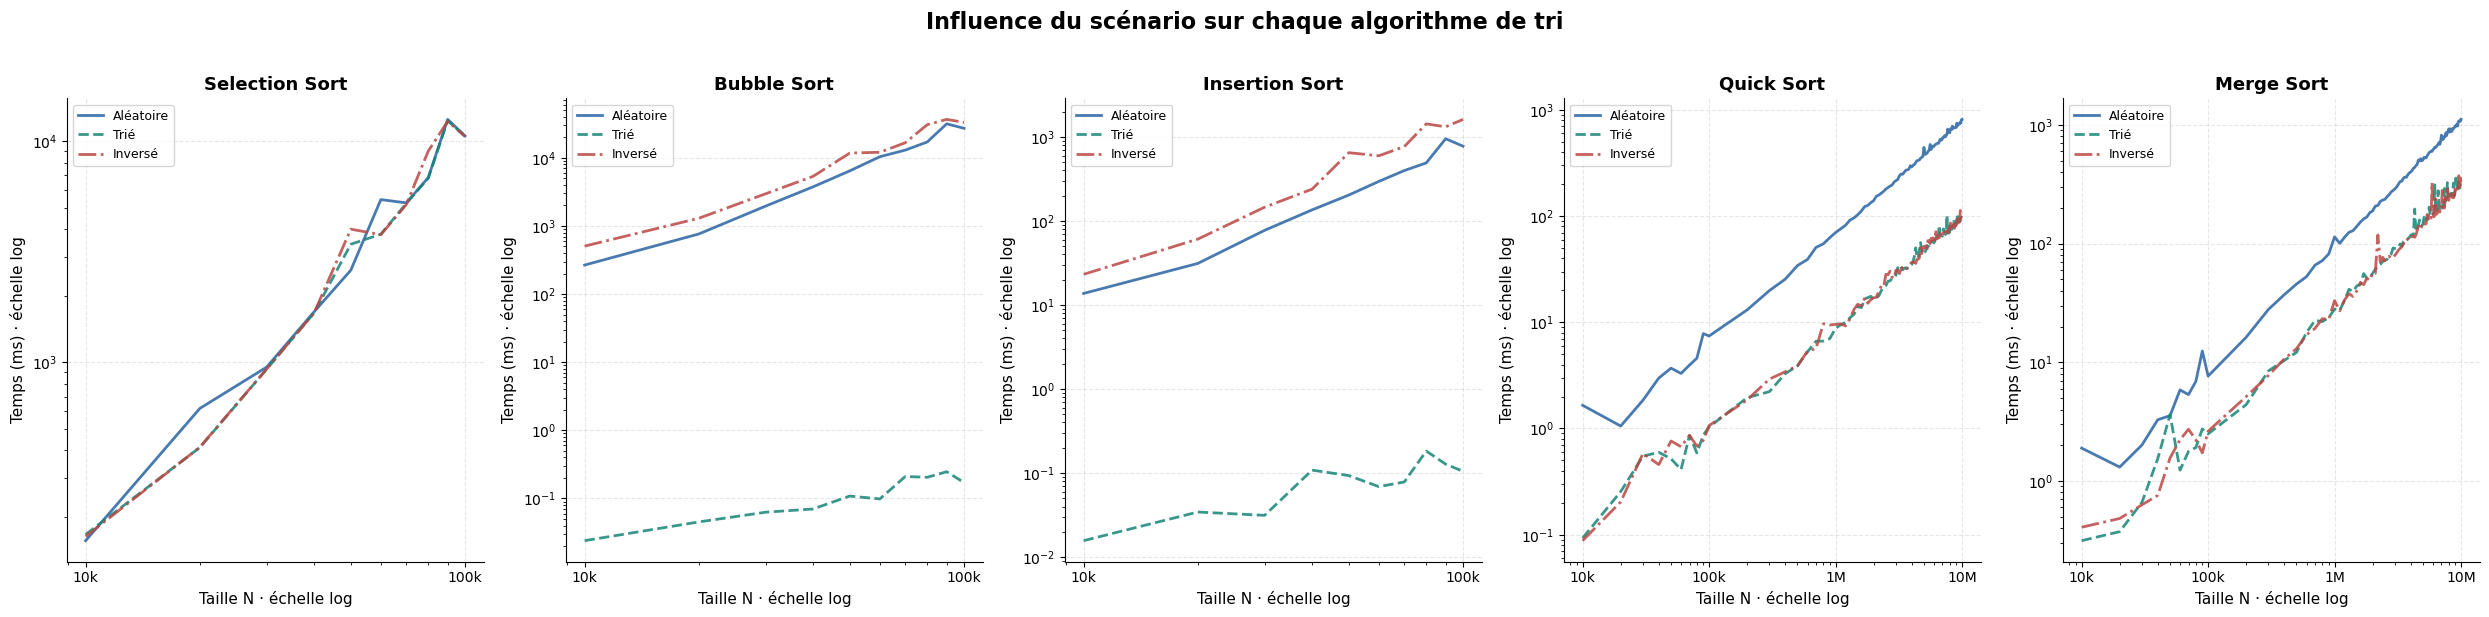

Figure enregistrée : graph2_impact_scenario.png


In [3]:
# Séparer les tris O(n²) et O(n log n) car leurs échelles sont très différentes
quadratic = ['Selection Sort', 'Bubble Sort', 'Insertion Sort']
fast = ['Quick Sort', 'Merge Sort']

quad_algos = [a for a in algos if a in quadratic]
fast_algos = [a for a in algos if a in fast]

n_plots = len(quad_algos) + len(fast_algos)
fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 6))
fig.suptitle('Influence du scénario sur chaque algorithme de tri',
             fontsize=16, fontweight='bold', y=1.02)

all_algos_ordered = list(quad_algos) + list(fast_algos)

for idx, algo in enumerate(all_algos_ordered):
    ax = axes[idx]
    sub = df[df['Nom_Algo'] == algo]

    for scenario in scenarios:
        data = sub[sub['Scenario'] == scenario].sort_values('Taille')
        if data.empty:
            continue
        ax.plot(data['Taille'], data['Temps'],
                label=scenario_labels[scenario],
                color=scenario_colors.get(scenario, 'gray'),
                linestyle=scenario_styles.get(scenario, '-'),
                linewidth=2, alpha=0.85)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(algo, fontsize=13, fontweight='bold')
    ax.set_xlabel('Taille N · échelle log', fontsize=11)
    ax.set_ylabel('Temps (ms) · échelle log', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_n))
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())

plt.tight_layout()
save_figure(fig, 'graph2_impact_scenario.png')


---
## G2 bis. Barres groupées : pourquoi Quick et Merge semblaient absents ?

**Les mesures existent.** Dans le graphique initial, les barres partageaient
un axe Y linéaire : des moyennes de **0,502 à 5,134 ms** pour Quick/Merge
étaient presque invisibles à côté des **15 032,498 ms** de Bubble en inversé.
Bubble et Insertion sur données triées étaient encore plus proches de l'axe.

La correction utilise un **axe Y logarithmique** et affiche la valeur au-dessus
de chaque barre. Il faut comparer les valeurs et les rapports : la longueur des
barres n'est plus proportionnelle au temps. Leur base est un seuil positif
commun, inférieur au plus petit temps, car le zéro n'existe pas sur cet axe.

Les moyennes sont calculées sur l'**intersection réelle des tailles** pour
tous les couples (algorithme, scénario) : ici 10 000 à 100 000 par pas de 10 000,
chaque taille ayant le même poids. Il ne s'agit pas de répétitions d'un test à
taille fixe. Aucune donnée manquante n'est remplacée par zéro.


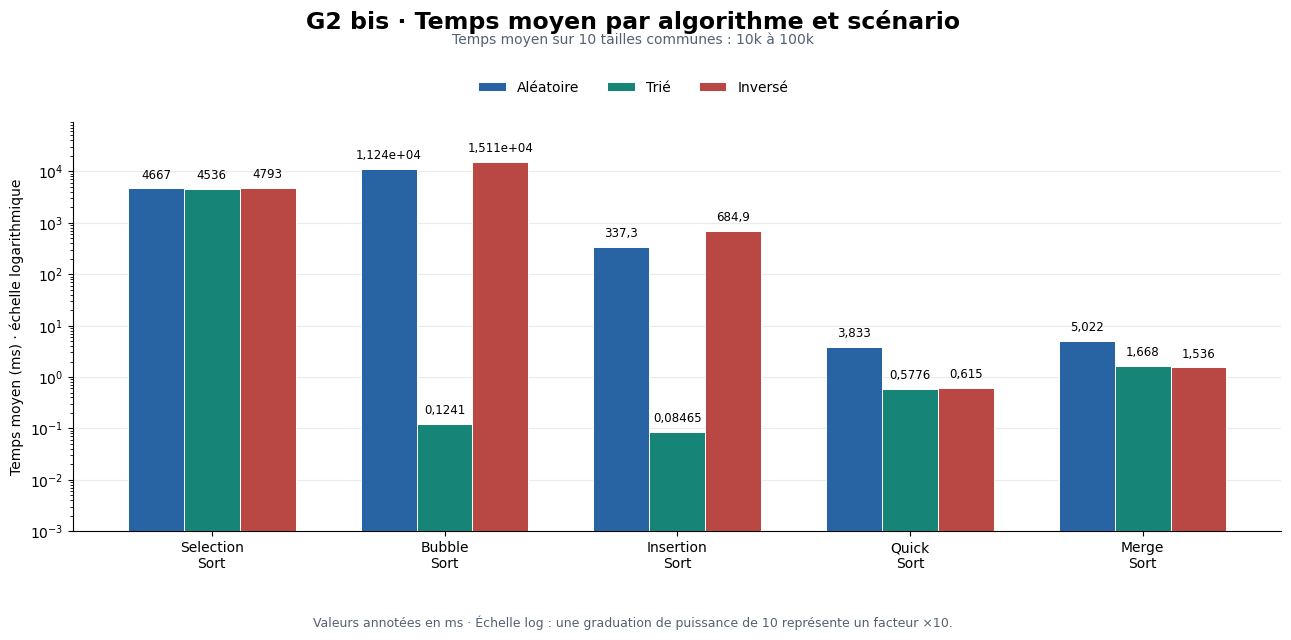

Figure enregistrée : graph2b_barres_scenario.png


Scenario,Aléatoire,Trié,Inversé
Temps moyen (ms),,,
Selection Sort,4666.94312,4535.71934,4793.16315
Bubble Sort,11238.06828,0.12407,15111.09527
Insertion Sort,337.33258,0.08465,684.91944
Quick Sort,3.83347,0.57757,0.61504
Merge Sort,5.02218,1.66758,1.53637


In [4]:
phase1 = df[df['Taille'].isin(common_sizes)]
mean_times = (phase1.groupby(['Nom_Algo', 'Scenario'])['Temps'].mean()
              .unstack().reindex(index=algos, columns=scenarios))
if mean_times.isna().any().any() or (mean_times <= 0).any().any():
    raise ValueError('Moyennes manquantes ou non positives : vérifier les données avant le tracé logarithmique.')

fig, ax = plt.subplots(figsize=(13.5, 6.6))
fig.subplots_adjust(top=0.81, bottom=0.19, left=0.085, right=0.98)
fig.suptitle('G2 bis · Temps moyen par algorithme et scénario', y=0.98, fontsize=17, fontweight='bold')
fig.text(0.5, 0.928, f'Temps moyen sur {len(common_sizes)} tailles communes : {format_n(min(common_sizes))} à {format_n(max(common_sizes))}',
         ha='center', color='#526173')
x = np.arange(len(algos))
width = 0.24
bar_floor = 10 ** (np.floor(np.log10(mean_times.to_numpy().min())) - 1)
for i, scenario in enumerate(scenarios):
    values = mean_times[scenario].to_numpy()
    # Le sommet doit rester exactement à T, malgré la base strictement positive.
    bars = ax.bar(x + (i - 1) * width, values - bar_floor, width, bottom=bar_floor,
                  label=scenario_labels[scenario], color=scenario_colors[scenario],
                  edgecolor='white', linewidth=0.7, zorder=3)
    for bar, value in zip(bars, values):
        ax.annotate(format_fr(value, 4), (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
ax.set_yscale('log')
ax.set_ylim(bar_floor, mean_times.to_numpy().max() * 6)
ax.set_ylabel('Temps moyen (ms) · échelle logarithmique')
ax.set_xticks(x)
ax.set_xticklabels([a.replace(' Sort', '\nSort') for a in algos])
ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=10))
ax.grid(True, axis='y', which='major', alpha=0.25, zorder=0)
fig.legend(*ax.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 0.892), ncol=3, frameon=False)
fig.text(0.5, 0.045, 'Valeurs annotées en ms · Échelle log : une graduation de puissance de 10 représente un facteur ×10.',
         ha='center', fontsize=9, color='#526173')
save_figure(fig, 'graph2b_barres_scenario.png')
display(mean_times.rename(columns=scenario_labels).round(5).rename_axis('Temps moyen (ms)'))


---
## 3️⃣ Configuration PC et influence sur les performances

La configuration du PC est lue depuis `src/data/pc_config.txt`.  
On affiche un résumé des performances avec la config en contexte, et on analyse le débit (éléments triés par seconde) pour décrire les résultats sur cette machine. Une seule configuration ne permet pas d'isoler un effet causal du matériel.

✅ 744 lignes | 1 machine(s) :
    • AMD Ryzen 5 Pro 6650U, 32 Go RAM, Windows 11  (744 lignes)


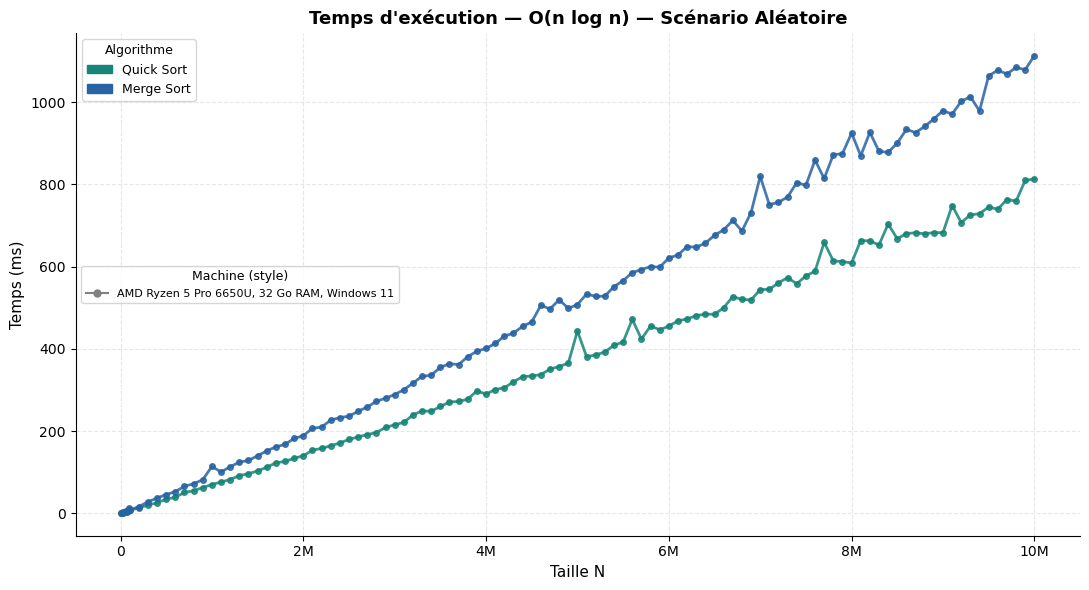

Figure enregistrée : graph_multiPC_nlogn_aleatoire.png


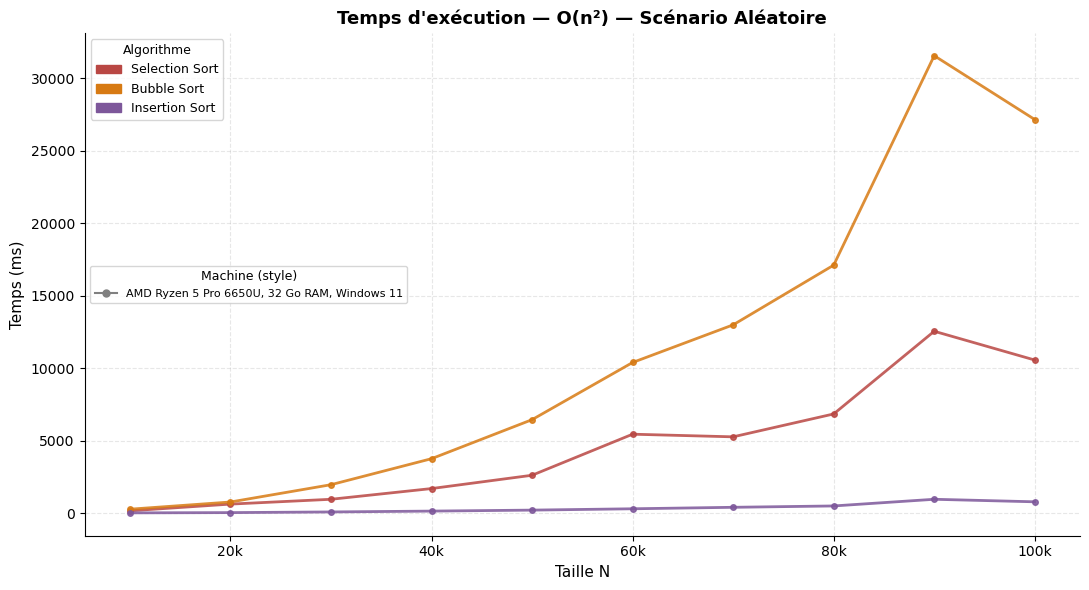

Figure enregistrée : graph_multiPC_quad_aleatoire.png


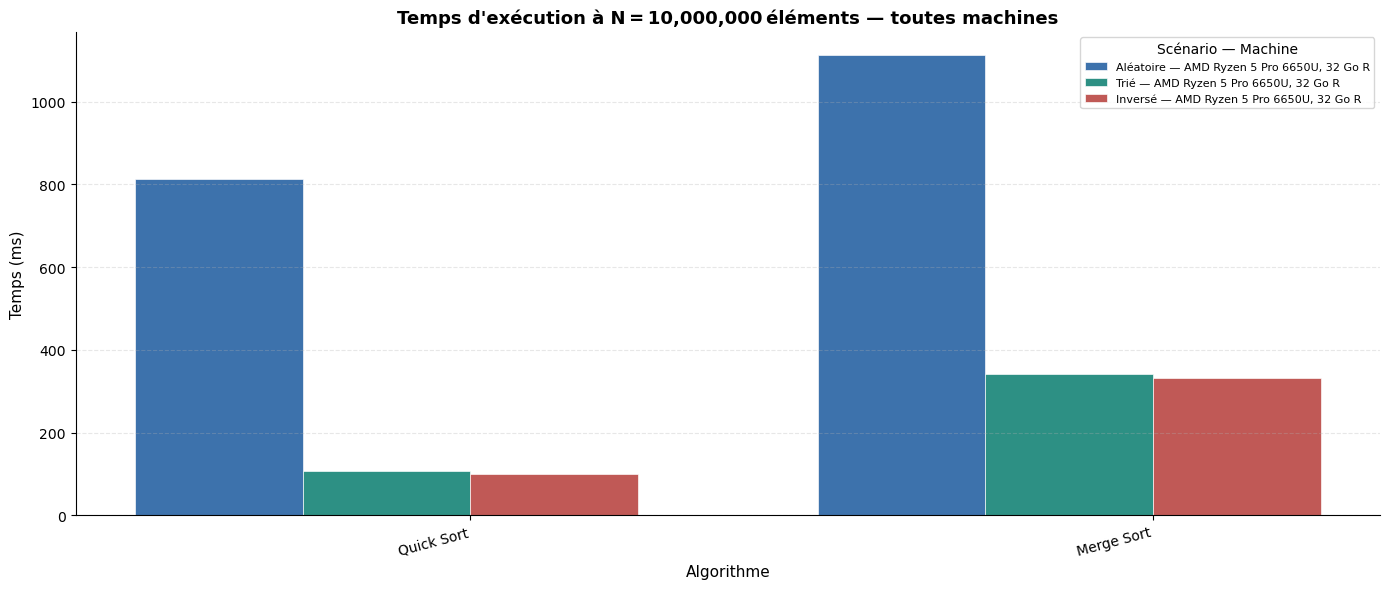

Figure enregistrée : graph_multiPC_resume_max_taille.png


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# Graphe multi-machines : temps d'exécution, scénario Aléatoire
# (Graphe A : O(n log n)  |  Graphe B : O(n²)  |  Graphe D : barres N_max)
#
# Réutilise les variables déjà définies dans la cellule d'init :
#   df, DATA_DIR, colors, markers, scenario_colors, scenario_styles,
#   scenario_labels, quadratic, fast, algos, scenarios, format_n, save_figure
# ─────────────────────────────────────────────────────────────────────────────
import glob
import matplotlib.patches as mpatches

# ── 1. Chargement multi-machines ─────────────────────────────────────────────
# Lit results_*.csv en plus du df déjà chargé.
# Si plusieurs fichiers existent, on les fusionne ; sinon on réutilise df.

def _load_all_results(data_dir):
    """Retourne un DataFrame fusionné de tous les results_*.csv (+ results.csv)."""
    frames = []
    for path in sorted(glob.glob(str(data_dir / 'results_*.csv'))):
        tmp = pd.read_csv(path)
        tmp.columns = tmp.columns.str.strip()
        for col in ['Scenario', 'Nom_Algo']:
            tmp[col] = tmp[col].astype('string').str.strip()
        for col in ['Taille', 'Temps']:
            tmp[col] = pd.to_numeric(tmp[col], errors='coerce')
        if 'PC_Config' not in tmp.columns:
            slug = Path(path).stem.replace('results_', '') or 'machine'
            tmp['PC_Config'] = slug
        tmp['Temps'] = tmp['Temps'] * 1000   # secondes → ms
        frames.append(tmp)

    if not frames:
        # Aucun results_*.csv : utiliser le df déjà chargé (cellule init)
        df_multi = df.copy()
        # PC_Config depuis pc_config.txt ou 'Machine inconnue'
        cfg_path = data_dir / 'pc_config.txt'
        pc = cfg_path.read_text(encoding='utf-8').strip().splitlines()[0] if cfg_path.exists() else 'Machine inconnue'
        df_multi['PC_Config'] = pc
        return df_multi

    return pd.concat(frames, ignore_index=True)

df_multi = _load_all_results(DATA_DIR)
machines = sorted(df_multi['PC_Config'].unique())

print(f"✅ {len(df_multi)} lignes | {len(machines)} machine(s) :")
for m in machines:
    n = len(df_multi[df_multi['PC_Config'] == m])
    print(f"    • {m}  ({n} lignes)")

# ── 2. Encodage visuel par machine ────────────────────────────────────────────
# Couleur algo déjà dans `colors` ; on ajoute style de ligne + marqueur par machine
_LINE_STYLES    = ['-', '--', '-.', ':', (0, (5,2)), (0, (3,1,1,1))]
_MARKERS        = ['o', 's', '^', 'D', 'v', 'P']
machine_style   = {m: _LINE_STYLES[i % len(_LINE_STYLES)] for i, m in enumerate(machines)}
machine_marker  = {m: _MARKERS   [i % len(_MARKERS)]      for i, m in enumerate(machines)}

def _machine_legend_handles():
    """Handles pour la légende secondaire (style de ligne = machine)."""
    return [
        plt.Line2D([0], [0], color='gray',
                   linestyle=machine_style[m],
                   marker=machine_marker[m],
                   markersize=5,
                   label=m[:55])
        for m in machines
    ]

# ── 3. Graphe A — O(n log n), scénario Aléatoire ─────────────────────────────
df_alea_fast = df_multi[(df_multi['Scenario'] == 'Aleatoire') &
                         (df_multi['Nom_Algo'].isin(fast))]

fig, ax = plt.subplots(figsize=(11, 6))
for algo in fast:
    for machine in machines:
        data = df_alea_fast[(df_alea_fast['Nom_Algo'] == algo) &
                            (df_alea_fast['PC_Config'] == machine)].sort_values('Taille')
        if data.empty:
            continue
        ax.plot(data['Taille'], data['Temps'],
                color=colors[algo],
                linestyle=machine_style[machine],
                marker=machine_marker[machine],
                markersize=4, linewidth=2, alpha=0.85)

ax.set_title("Temps d'exécution — O(n log n) — Scénario Aléatoire",
             fontsize=13, fontweight='bold')
ax.set_xlabel('Taille N', fontsize=11)
ax.set_ylabel('Temps (ms)', fontsize=11)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_n))
ax.grid(True, alpha=0.3, linestyle='--')

algo_handles = [mpatches.Patch(color=colors[a], label=a) for a in fast]
mach_handles = _machine_legend_handles()
leg1 = ax.legend(handles=algo_handles,  title='Algorithme',     loc='upper left',  fontsize=9, title_fontsize=9)
ax.add_artist(leg1)
ax.legend(handles=mach_handles, title='Machine (style)', loc='center left', fontsize=8, title_fontsize=9)

plt.tight_layout()
save_figure(fig, 'graph_multiPC_nlogn_aleatoire.png')

# ── 4. Graphe B — O(n²), scénario Aléatoire ──────────────────────────────────
df_alea_quad = df_multi[(df_multi['Scenario'] == 'Aleatoire') &
                         (df_multi['Nom_Algo'].isin(quadratic))]

fig, ax = plt.subplots(figsize=(11, 6))
for algo in quadratic:
    for machine in machines:
        data = df_alea_quad[(df_alea_quad['Nom_Algo'] == algo) &
                             (df_alea_quad['PC_Config'] == machine)].sort_values('Taille')
        if data.empty:
            continue
        ax.plot(data['Taille'], data['Temps'],
                color=colors[algo],
                linestyle=machine_style[machine],
                marker=machine_marker[machine],
                markersize=4, linewidth=2, alpha=0.85)

ax.set_title("Temps d'exécution — O(n²) — Scénario Aléatoire",
             fontsize=13, fontweight='bold')
ax.set_xlabel('Taille N', fontsize=11)
ax.set_ylabel('Temps (ms)', fontsize=11)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_n))
ax.grid(True, alpha=0.3, linestyle='--')

algo_handles = [mpatches.Patch(color=colors[a], label=a) for a in quadratic]
mach_handles = _machine_legend_handles()
leg1 = ax.legend(handles=algo_handles,  title='Algorithme',     loc='upper left',  fontsize=9, title_fontsize=9)
ax.add_artist(leg1)
ax.legend(handles=mach_handles, title='Machine (style)', loc='center left', fontsize=8, title_fontsize=9)

plt.tight_layout()
save_figure(fig, 'graph_multiPC_quad_aleatoire.png')

# ── 5. Graphe D — Barres comparatives à N_max ────────────────────────────────
n_max   = df_multi['Taille'].max()
df_max  = df_multi[df_multi['Taille'] == n_max]
pivot   = (df_max.groupby(['Nom_Algo', 'PC_Config', 'Scenario'])['Temps']
                 .mean().reset_index())

algo_order  = [a for a in quadratic + fast if a in pivot['Nom_Algo'].values]
n_m = len(machines)
n_s = len(scenarios)
n_a = len(algo_order)

bar_w      = 0.7 / (n_m * n_s)
group_w    = bar_w * n_m * n_s + 0.25
x_centers  = [i * group_w for i in range(n_a)]
hatches    = ['', '//', 'xx', r'\\', '..', '++']

fig, ax = plt.subplots(figsize=(14, 6))
for m_idx, machine in enumerate(machines):
    for s_idx, scenario in enumerate(scenarios):
        offsets = [
            xc + (m_idx * n_s + s_idx) * bar_w - (n_m * n_s * bar_w) / 2
            for xc in x_centers
        ]
        heights = []
        for algo in algo_order:
            row = pivot[(pivot['Nom_Algo'] == algo) &
                        (pivot['PC_Config'] == machine) &
                        (pivot['Scenario']  == scenario)]
            heights.append(float(row['Temps'].values[0]) if not row.empty else 0.0)

        ax.bar(offsets, heights,
               width=bar_w,
               color=scenario_colors.get(scenario, 'gray'),
               alpha=max(0.9 - m_idx * 0.18, 0.35),
               hatch=hatches[m_idx % len(hatches)] if n_m > 1 else '',
               edgecolor='white', linewidth=0.5,
               label=f"{scenario_labels.get(scenario, scenario)} — {machine[:30]}")

ax.set_title(f"Temps d'exécution à N\u202f=\u202f{int(n_max):,}\u202féléments — toutes machines",
             fontsize=13, fontweight='bold')
ax.set_xlabel('Algorithme', fontsize=11)
ax.set_ylabel('Temps (ms)', fontsize=11)
ax.set_xticks(x_centers)
ax.set_xticklabels(algo_order, rotation=15, ha='right')
ax.grid(True, axis='y', alpha=0.3, linestyle='--')

# Légende dédupliquée
seen, unique_h, unique_l = set(), [], []
for h, l in zip(*ax.get_legend_handles_labels()):
    if l not in seen:
        seen.add(l); unique_h.append(h); unique_l.append(l)
ax.legend(unique_h, unique_l, fontsize=8, ncol=max(1, n_m),
          title='Scénario — Machine', loc='upper right')

plt.tight_layout()
save_figure(fig, 'graph_multiPC_resume_max_taille.png')


---
## G5. Facteur d'impact du scénario à N = 50 000

Chaque case représente, **pour le même algorithme et la même taille** :

$$R = \frac{T(\mathrm{scénario})}{T(\mathrm{aléatoire})}.$$

- $R=1$ : même temps que l'aléatoire ; la colonne de référence vaut 1 par construction.
- $R<1$ : plus rapide (bleu) ; $R>1$ : plus lent (rouge).
- Couleurs logarithmiques et annotations numériques : les rapports très faibles
  restent **strictement positifs**, ils ne sont ni arrondis à zéro ni remplacés
  par un epsilon. Chaque case indique aussi le temps absolu pour contextualiser le ratio.

**N = 50 000** est la taille demandée et une taille commune intermédiaire.
Le CSV fourni contient en réalité **dix tailles communes**, de 10 000 à
100 000 ; 50 000 n'est donc pas l'unique taille commune.

Les chiffres ci-dessous sont recalculés depuis le CSV actuel. Ils diffèrent
des exemples cités dans la demande (2,56 s ; 5,9 s ; 8,1 s). Le scénario inversé
est le plus lent des trois pour Bubble et Insertion à cette taille ; ces trois
entrées ne suffisent pas à établir le pire cas de chaque algorithme.

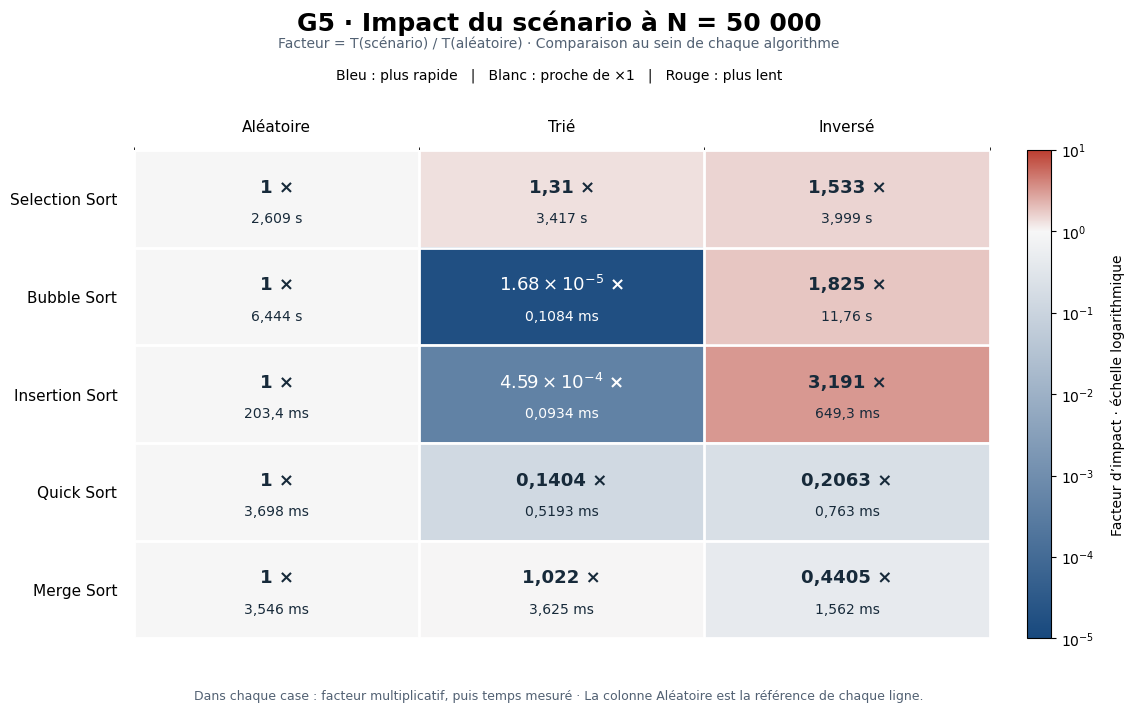

Figure enregistrée : graph5_heatmap_impact_scenario.png


**Lecture des mesures à N = 50 000 :**

- **Selection** : 2,609 s (aléatoire), 3,417 s (trié), 3,999 s (inversé). Les facteurs sont proches de 1 : 1,31 et 1,533.
- **Bubble** : 6,444 s → 11,76 s en inversé, soit ×1,825.
- **Données triées** : Bubble = 0,1084 ms, Insertion = 0,0934 ms. Leurs facteurs très faibles illustrent le meilleur cas linéaire ; ils ne sont pas nuls.
- Ces ratios décrivent cette mesure et cette implémentation ; ils ne constituent pas des intervalles de confiance.

In [6]:
N_TARGET = 50_000
times_50k = (df.loc[df['Taille'] == N_TARGET]
             .pivot(index='Nom_Algo', columns='Scenario', values='Temps_s')
             .reindex(index=algos, columns=scenarios))
if times_50k.isna().any().any() or (times_50k <= 0).any().any():
    raise ValueError(f'G5 exige les 15 temps strictement positifs à N = {N_TARGET:,}. Aucune interpolation ni imputation.')
impact = times_50k.div(times_50k['Aleatoire'], axis=0)

# Normalisation réellement logarithmique ; la couleur neutre est placée à R=1.
lo_exp = min(-1, int(np.floor(np.log10(impact.to_numpy().min()))))
hi_exp = max(1, int(np.ceil(np.log10(impact.to_numpy().max()))))
norm = LogNorm(vmin=10.0 ** lo_exp, vmax=10.0 ** hi_exp)
neutral_position = float(norm(1.0))
cmap = LinearSegmentedColormap.from_list('scenario_impact',
        [(0, '#17487d'), (neutral_position, '#f7f7f7'), (1, '#bb3d2f')], N=1024)

fig, ax = plt.subplots(figsize=(12.5, 7.4))
fig.subplots_adjust(top=0.79, bottom=0.13, left=0.16, right=0.90)
fig.suptitle('G5 · Impact du scénario à N = 50 000', fontsize=18, fontweight='bold', y=0.98)
fig.text(0.5, 0.928, 'Facteur = T(scénario) / T(aléatoire) · Comparaison au sein de chaque algorithme',
         ha='center', color='#526173')
fig.text(0.5, 0.886, 'Bleu : plus rapide   |   Blanc : proche de ×1   |   Rouge : plus lent',
         ha='center', fontsize=10)
im = ax.imshow(impact.to_numpy(), cmap=cmap, norm=norm, aspect='auto', interpolation='nearest')
ax.set_xticks(range(len(scenarios)))
ax.set_xticklabels([scenario_labels[s] for s in scenarios], fontsize=11)
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0, pad=11)
ax.set_yticks(range(len(algos)))
ax.set_yticklabels(algos, fontsize=11)
ax.tick_params(axis='y', length=0, pad=12)
ax.set_xticks(np.arange(-0.5, len(scenarios), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(algos), 1), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='minor', bottom=False, left=False)
for spine in ax.spines.values():
    spine.set_visible(False)

def ratio_label(value):
    if value < 0.001:
        exponent = int(np.floor(np.log10(value)))
        mantissa = value / 10.0 ** exponent
        return rf'${mantissa:.2f}\times10^{{{exponent}}}$ ×'
    return format_fr(value, 4) + ' ×'

def time_label(seconds):
    if seconds >= 1:
        return format_fr(seconds, 4) + ' s'
    return format_fr(seconds * 1000, 4) + ' ms'

for i, algo in enumerate(algos):
    for j, scenario in enumerate(scenarios):
        ratio = impact.loc[algo, scenario]
        rgb = cmap(norm(ratio))[:3]
        luminance = 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2]
        text_color = 'white' if luminance < 0.53 else '#172a3a'
        ax.text(j, i - 0.12, ratio_label(ratio), ha='center', va='center',
                fontsize=13, fontweight='bold', color=text_color)
        ax.text(j, i + 0.20, time_label(times_50k.loc[algo, scenario]), ha='center', va='center',
                fontsize=10, color=text_color)

cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04,
                  ticks=10.0 ** np.arange(lo_exp, hi_exp + 1))
cb.set_label('Facteur d’impact · échelle logarithmique', labelpad=12)
cb.ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext(base=10))
cb.ax.minorticks_off()
fig.text(0.5, 0.048, 'Dans chaque case : facteur multiplicatif, puis temps mesuré · La colonne Aléatoire est la référence de chaque ligne.',
         ha='center', fontsize=9, color='#526173')
save_figure(fig, 'graph5_heatmap_impact_scenario.png')

selection = times_50k.loc['Selection Sort']
bubble = times_50k.loc['Bubble Sort']
display(Markdown(
    '**Lecture des mesures à N = 50 000 :**\n\n'
    f"- **Selection** : {format_fr(selection['Aleatoire'], 4)} s (aléatoire), "
    f"{format_fr(selection['Trie'], 4)} s (trié), {format_fr(selection['Inverse'], 4)} s (inversé). "
    f"Les facteurs sont proches de 1 : {format_fr(impact.loc['Selection Sort', 'Trie'], 4)} et "
    f"{format_fr(impact.loc['Selection Sort', 'Inverse'], 4)}.\n"
    f"- **Bubble** : {format_fr(bubble['Aleatoire'], 4)} s → {format_fr(bubble['Inverse'], 4)} s en inversé, "
    f"soit ×{format_fr(impact.loc['Bubble Sort', 'Inverse'], 4)}.\n"
    f"- **Données triées** : Bubble = {time_label(bubble['Trie'])}, "
    f"Insertion = {time_label(times_50k.loc['Insertion Sort', 'Trie'])}. "
    'Leurs facteurs très faibles illustrent le meilleur cas linéaire ; ils ne sont pas nuls.\n'
    '- Ces ratios décrivent cette mesure et cette implémentation ; ils ne constituent pas des intervalles de confiance.'
))

---
## Résumé des figures

| Graphe | Contenu | Choix de lecture |
|---|---|---|
| **G1** | Tous les tris par scénario, vue complète et zoom commun | Axes adaptés ; mêmes limites verticales |
| **G2** | Scénarios comparés pour chaque tri | Courbes en log–log |
| **G2 bis** | Moyennes sur les mêmes tailles | Barres logarithmiques et valeurs annotées |
| **G3** | Configuration PC et débit | Description d'une machine, sans comparaison matérielle causale |
| **G4** | T/n² et T/(n log₂ n) | Constantes approximatives, meilleurs cas et écarts au modèle |
| **G5** | Facteurs scénario/aléatoire à N = 50 000 | Heatmap logarithmique avec facteurs et temps absolus |

**Reproductibilité :** les graphiques sont recalculés depuis le CSV fourni, sans
relancer le benchmark C. La comparaison des scénarios doit porter sur une même
taille, ou sur un ensemble identique de tailles comme en G2 bis. Pour quantifier
la variabilité, il faudrait plusieurs répétitions par triplet et des statistiques
de dispersion ; aucune précision supplémentaire n'est inventée ici.